In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from scipy import stats

In [2]:
df_raw = pd.read_csv(r"C:\\Users\\rbhad\\OneDrive\\Documents\\Machine Learning\\Project\\Bikes\\bikes.csv")

In [3]:
df_raw.head()

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500


In [4]:
df_raw['owner'].value_counts()

owner
first owner             6817
second owner             833
third owner              134
fourth owner or more      73
Name: count, dtype: int64

In [5]:
df_raw.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [6]:
df_raw.duplicated().sum()

np.int64(0)

In [7]:
df_raw.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [8]:
df_raw['price'].describe()

count    7.857000e+03
mean     1.067913e+05
std      1.389261e+05
min      0.000000e+00
25%      4.200000e+04
50%      7.500000e+04
75%      1.250000e+05
max      3.000000e+06
Name: price, dtype: float64

In [9]:
df_raw[['kms_driven', 'mileage', 'power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [10]:
#function to convert string values to numeric values
def convert_to_num(value):
    if pd.isna(value):
        return np.nan
    value=str(value).replace(',', '')
    number=''
    dot_used=False

    for i in value:
        if i.isdigit():
            number+=i
        elif i=='.' and not dot_used:
            dot_used=True
        elif number:
            break

    return float(number) if number else np.nan

In [11]:
df_raw.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [12]:
column_names =['model_year', 'kms_driven', 'mileage', 'power']
for i in column_names:
    df_raw[i] = df_raw[i].apply(convert_to_num)

In [13]:
df_raw.head()

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.0,17000.0,first owner,hyderabad,35.0,19.0,63500
1,Royal Enfield Classic 350cc 2016,2016.0,50000.0,first owner,hyderabad,35.0,1980.0,115000
2,Hyosung GT250R 2012,2012.0,14795.0,first owner,hyderabad,30.0,28.0,300000
3,Bajaj Dominar 400 ABS 2017,2017.0,28.0,first owner,pondicherry,28.0,3450.0,100000
4,Jawa Perak 330cc 2020,2020.0,2000.0,first owner,bangalore,NaN,30.0,197500


In [14]:
df_raw.duplicated().sum()

np.int64(0)

In [15]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   model_name  7857 non-null   str    
 1   model_year  7857 non-null   float64
 2   kms_driven  7854 non-null   float64
 3   owner       7857 non-null   str    
 4   location    7838 non-null   str    
 5   mileage     7083 non-null   float64
 6   power       7826 non-null   float64
 7   price       7857 non-null   int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 491.2 KB


In [16]:
df=df_raw.dropna(subset='price')

In [17]:
df[df['price']>0]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.0,17000.0,first owner,hyderabad,35.0,19.0,63500
1,Royal Enfield Classic 350cc 2016,2016.0,50000.0,first owner,hyderabad,35.0,1980.0,115000
2,Hyosung GT250R 2012,2012.0,14795.0,first owner,hyderabad,30.0,28.0,300000
3,Bajaj Dominar 400 ABS 2017,2017.0,28.0,first owner,pondicherry,28.0,3450.0,100000
4,Jawa Perak 330cc 2020,2020.0,2000.0,first owner,bangalore,NaN,30.0,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.0,7000.0,first owner,agra,42.0,16.0,55000
7853,Bajaj Discover 100cc 2015,2015.0,80.0,first owner,delhi,80.0,77.0,28000
7854,Bajaj Pulsar 180cc 2016,2016.0,6407.0,first owner,bangalore,65.0,17.0,61740
7855,Bajaj V15 150cc 2016,2016.0,7524.0,first owner,bangalore,57.0,1180.0,49000


In [18]:
df[df['model_year']<1990]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
1691,Royal Enfield Bullet 350 cc 1982,1982.0,22000.0,first owner,pune,NaN,NaN,150000
1716,Royal Enfield Bullet 350 cc 1982,1982.0,16245.0,first owner,delhi,NaN,NaN,70000
2211,Bajaj Pulsar NS 200cc 2013,1950.0,35.0,first owner,noida,35.0,2319.0,55000
2487,Royal Enfield Bullet 350 cc 1982,1982.0,3000.0,second owner,lalitpur,NaN,NaN,130000
2638,Ideal Jawa Yezdi Delux 250 cc 1978,1978.0,85000.0,first owner,chikamaglur,NaN,NaN,100000
2714,Royal Enfield Bullet 350 cc 1982,1982.0,21000.0,first owner,nashik,NaN,NaN,170000
3088,Royal Enfield Bullet 350 cc 1982,1982.0,10000.0,first owner,mumbai,NaN,NaN,60000
3429,Royal Enfield‎ Bullet 350cc 1970,1970.0,5000.0,third owner,pune,25.0,1980.0,190000
4174,Royal Enfield Standard 350cc 1985,1985.0,40.0,third owner,kolhapur,40.0,18.0,125000
4258,Bajaj Pulsar NS 200cc 2013,1950.0,35.0,third owner,khalilabad,35.0,2319.0,55000


In [19]:
pd.Timestamp.now().year

2026

In [20]:
df['model_year']=df['model_year'].astype(int)

In [21]:
df['kms_driven']=df['kms_driven'].fillna(df['kms_driven'].median())

In [22]:
df.isnull().sum()

model_name      0
model_year      0
kms_driven      0
owner           0
location       19
mileage       774
power          31
price           0
dtype: int64

In [23]:
df['location']=df['location'].fillna('unknown')

In [24]:
df.isnull().sum()

model_name      0
model_year      0
kms_driven      0
owner           0
location        0
mileage       774
power          31
price           0
dtype: int64

In [25]:
df.isnull().sum()

model_name      0
model_year      0
kms_driven      0
owner           0
location        0
mileage       774
power          31
price           0
dtype: int64

In [26]:
df["mileage"]=df["mileage"].dropna()

In [27]:
if "model_year" in df.columns:
    current_year = pd.Timestamp.today().year
    df["bike_age"] = current_year - df["model_year"]

In [28]:
df.isnull().sum()

model_name      0
model_year      0
kms_driven      0
owner           0
location        0
mileage       774
power          31
price           0
bike_age        0
dtype: int64

In [29]:
df = df.dropna(subset=['mileage', 'power'])

In [30]:
df.isnull().sum()

model_name    0
model_year    0
kms_driven    0
owner         0
location      0
mileage       0
power         0
price         0
bike_age      0
dtype: int64

In [31]:
df_clean = df.copy()
df_clean.to_csv("bikes_cleaned", index=False)


In [32]:
df_clean.head()

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age
0,Bajaj Avenger Cruise 220 2017,2017,17000.0,first owner,hyderabad,35.0,19.0,63500,9
1,Royal Enfield Classic 350cc 2016,2016,50000.0,first owner,hyderabad,35.0,1980.0,115000,10
2,Hyosung GT250R 2012,2012,14795.0,first owner,hyderabad,30.0,28.0,300000,14
3,Bajaj Dominar 400 ABS 2017,2017,28.0,first owner,pondicherry,28.0,3450.0,100000,9
5,KTM Duke 200cc 2012,2012,24561.0,third owner,bangalore,35.0,25.0,63400,14


In [33]:
df_clean['price'].describe()

count    7.079000e+03
mean     1.024330e+05
std      1.329577e+05
min      0.000000e+00
25%      4.000000e+04
50%      7.000000e+04
75%      1.200000e+05
max      1.900000e+06
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

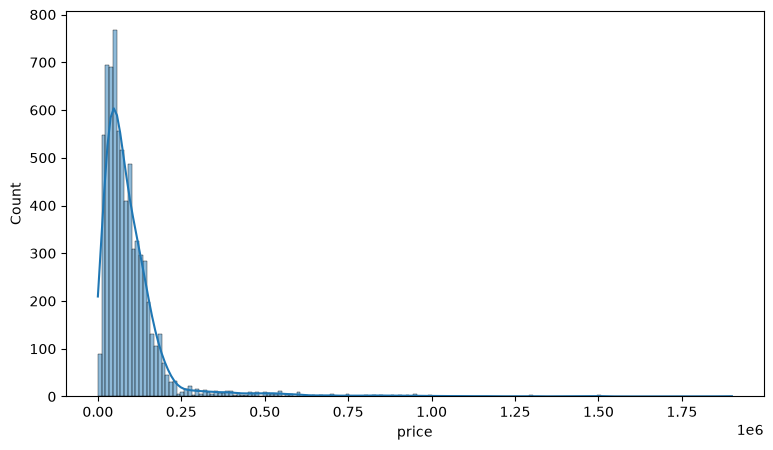

In [34]:
plt.figure(figsize=(9,5))
sns.histplot(df_clean['price'], kde=True)

<Axes: xlabel='price'>

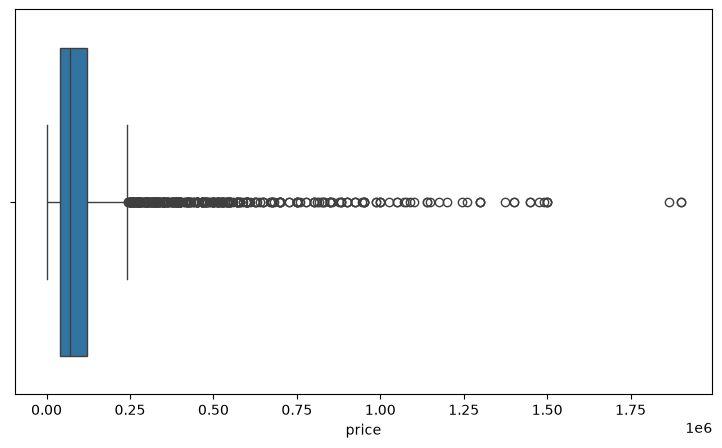

In [35]:
plt.figure(figsize=(9,5))
sns.boxplot(x=df_clean['price'])

In [36]:
df_clean['brand']=df_clean['model_name'].str.split().str[0]

In [37]:
df_clean['brand']=df_clean['brand'].str.lower()

In [38]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index()

In [39]:
brand_stats[brand_stats['count']>10].sort_values(by='median', ascending=False)

,brand,median,mean,count
4,ducati,881875.0,979199.133333,15
18,triumph,738125.0,826819.900000,30
11,kawasaki,465000.0,499179.784615,65
5,harley-davidson,430000.0,493365.736196,163
2,benelli,259375.0,305429.810811,37
9,hyosung,200000.0,217526.078431,51
12,ktm,145250.0,148495.211823,406
20,um,125000.0,128446.007812,128
16,royal,120000.0,121665.957875,1638
17,suzuki,64200.0,88261.857988,169


In [40]:
brand_top_10=brand_stats[brand_stats['count']>10].sort_values(by='median', ascending=False).head(10)

In [41]:
brand_top_10

,brand,median,mean,count
4,ducati,881875.0,979199.133333,15
18,triumph,738125.0,826819.900000,30
11,kawasaki,465000.0,499179.784615,65
5,harley-davidson,430000.0,493365.736196,163
2,benelli,259375.0,305429.810811,37
9,hyosung,200000.0,217526.078431,51
12,ktm,145250.0,148495.211823,406
20,um,125000.0,128446.007812,128
16,royal,120000.0,121665.957875,1638
17,suzuki,64200.0,88261.857988,169


<Axes: xlabel='brand', ylabel='median'>

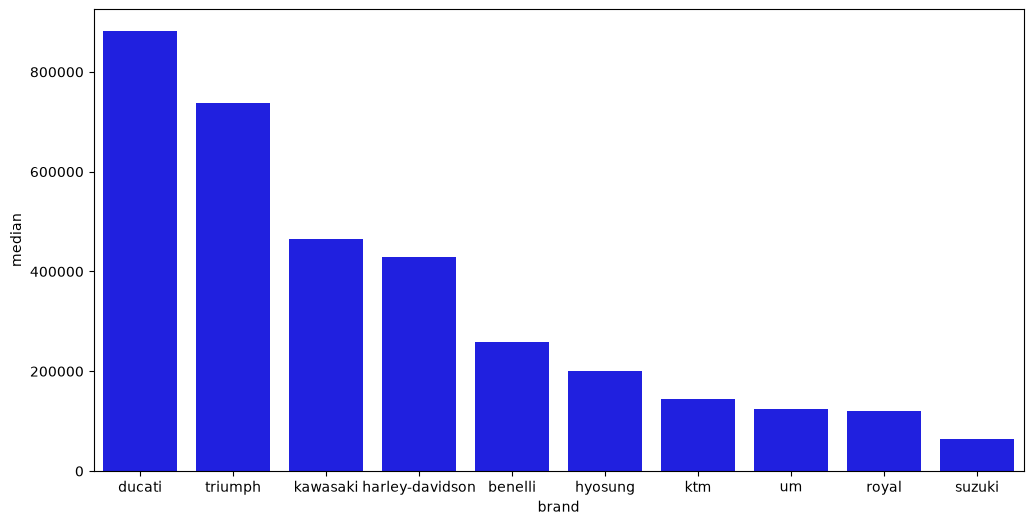

In [42]:
plt.figure(figsize=(12,6))
sns.barplot(data=brand_top_10, x='brand', y='median', color='blue')

<Axes: xlabel='kms_driven', ylabel='price'>

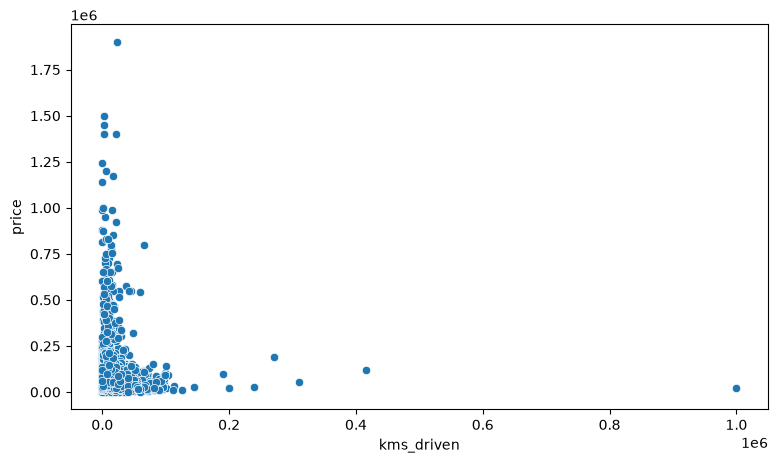

In [43]:
plot_data=df_clean.dropna(subset=['price','kms_driven'])
if len(plot_data) > 3000:
    plot_data = plot_data.sample(n=3000, random_state=42)

plt.figure(figsize=(9,5))
sns.scatterplot(data=plot_data, x='kms_driven', y='price')

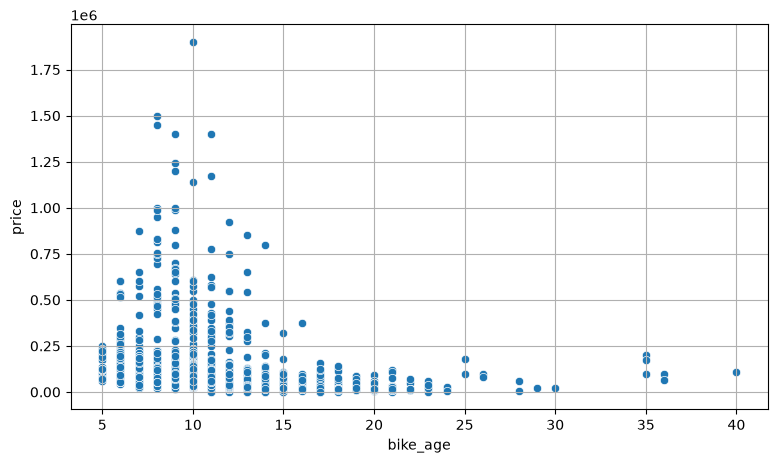

In [44]:
plot_data=df_clean.dropna(subset=['price','bike_age'])
if len(plot_data) > 3000:
    plot_data = plot_data.sample(n=3000, random_state=42)

plt.figure(figsize=(9,5))
sns.scatterplot(data=plot_data, x='bike_age', y='price')
plt.grid()

<Axes: >

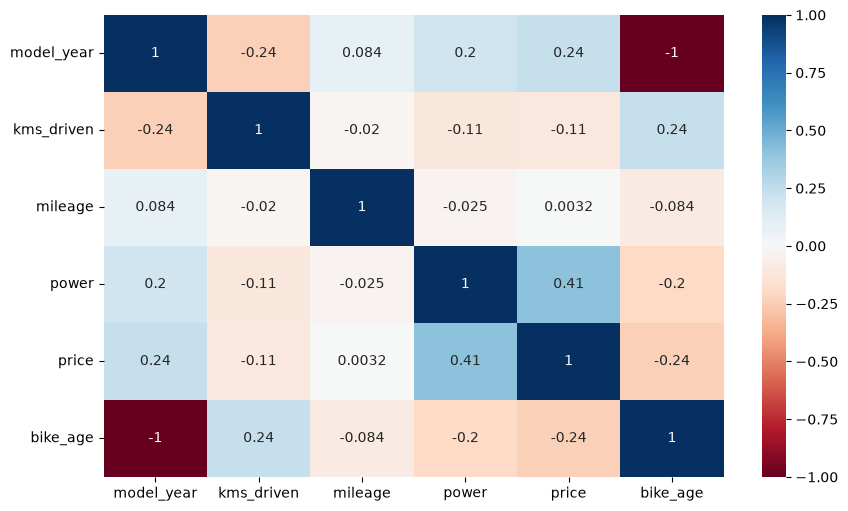

In [45]:
numeric_df= df_clean.select_dtypes(include=[np.number])

plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='RdBu')

In [46]:
df_clean.dropna(inplace=True)

C:\Users\rbhad\AppData\Local\Temp\ipykernel_16144\1832953665.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.dropna(inplace=True)


In [47]:
df_clean.reset_index(drop='First', inplace=True)

C:\Users\rbhad\AppData\Local\Temp\ipykernel_16144\3602144942.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.reset_index(drop='First', inplace=True)


In [50]:
data=df_clean.drop(['model_name', 'location'], axis=1)

In [52]:
x=data[['model_year', 'kms_driven', 'owner', 'mileage', 'power','bike_age', 'brand']]
y=data['price']

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y,random_state=42, test_size=0.2)


In [55]:
numerical_columns = x.select_dtypes(include=[np.number]).columns
categorical_columns = x.select_dtypes(exclude=[np.number]).columns

In [60]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer

In [ ]:
numerical_pipelines = Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])
categorical_pipelines = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('ohe', OneHotEncoder(handle_unknown='ignore'))])

In [65]:
transformer = []
if numerical_columns.any():
    transformer.append(numerical_pipelines)
if categorical_columns.any():
    transformer.append(categorical_pipelines)